# Empathic vs Non-Empathic Agent Comparison (FIXED)

This notebook compares two conditions with **FIXED** metrics tracking:
1. **Non-Empathic Agents** (`empathy_alpha = 0`): Agents only care about their own satisfaction
2. **Empathic Agents** (`empathy_alpha = 0.5`): Agents consider others' emotional state when consuming resources

## Fixes Applied

1. **Depletion Tracking**: Now checks resources AFTER each step (using `info['resources_remaining']`) to catch depletion events
2. **Different Seeds**: Uses different seeds for each condition to avoid identical random trajectories
3. **Better Metrics**: Tracks average resource count during episodes

## Environment Setup
- **Grid**: 5×5 (25 cells)
- **Agents**: 5
- **Initial Resources**: 10
- **Regeneration**: Dynamic (fewer resources = lower respawn probability)

## Metrics Tracked
1. **Resource Depletion Step**: Step at which resources FIRST reach 0 (or episode end if never depleted)
2. **Resources Remaining**: Number of resources left at episode end
3. **Average Resources During Episode**: Mean resource count throughout the episode
4. **Gini Coefficient**: Inequality measure of resource consumption across agents
5. **Average Inter-Agent Distance**: Mean Manhattan distance between all agent pairs
6. **Total Consumption per Agent**: How many resources each agent consumed
7. **Satisfaction Distribution**: Final satisfaction levels across agents

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict
import torch
import warnings
warnings.filterwarnings('ignore')

from env_2d import EmpathicGridEnv
from agent_2d import DQNAgent
from tqdm import tqdm
import time

# ============================================================
# GPU CONFIGURATION - Maximize Performance
# ============================================================
print("="*60)
print("HARDWARE CONFIGURATION")
print("="*60)

if torch.cuda.is_available():
    # Use GPU
    DEVICE = torch.device("cuda")
    print(f"✓ CUDA Available: Using GPU")
    print(f"  GPU: {torch.cuda.get_device_name(0)}")
    print(f"  CUDA Version: {torch.version.cuda}")
    print(f"  Memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")
    
    # Performance optimizations
    torch.backends.cudnn.benchmark = True  # Auto-tune for best performance
    torch.backends.cudnn.enabled = True
    print(f"  cuDNN Enabled: {torch.backends.cudnn.enabled}")
    print(f"  cuDNN Benchmark: {torch.backends.cudnn.benchmark}")
else:
    DEVICE = torch.device("cpu")
    print(f"✗ CUDA Not Available: Using CPU")
    # CPU optimizations
    torch.set_num_threads(torch.get_num_threads())
    print(f"  CPU Threads: {torch.get_num_threads()}")

print("="*60)
print("Imports completed successfully!")

HARDWARE CONFIGURATION
✓ CUDA Available: Using GPU
  GPU: NVIDIA GeForce RTX 4050 Laptop GPU
  CUDA Version: 12.1
  Memory: 6.4 GB
  cuDNN Enabled: True
  cuDNN Benchmark: True
Imports completed successfully!


In [2]:
def compute_gini_coefficient(values):
    """
    Compute the Gini coefficient for a list of values.
    Gini = 0 means perfect equality (everyone has the same)
    Gini = 1 means perfect inequality (one person has everything)
    """
    values = np.array(values, dtype=float)
    if len(values) == 0 or np.sum(values) == 0:
        return 0.0
    
    # Sort values
    sorted_values = np.sort(values)
    n = len(sorted_values)
    
    # Compute Gini using the formula: G = (2 * sum(i * x_i) - (n + 1) * sum(x_i)) / (n * sum(x_i))
    index = np.arange(1, n + 1)
    return (2 * np.sum(index * sorted_values) - (n + 1) * np.sum(sorted_values)) / (n * np.sum(sorted_values))


def compute_average_inter_agent_distance(positions):
    """
    Compute the average Manhattan distance between all pairs of agents.
    """
    if len(positions) < 2:
        return 0.0
    
    total_distance = 0
    num_pairs = 0
    
    for i in range(len(positions)):
        for j in range(i + 1, len(positions)):
            x1, y1 = positions[i]
            x2, y2 = positions[j]
            total_distance += abs(x1 - x2) + abs(y1 - y2)
            num_pairs += 1
    
    return total_distance / num_pairs if num_pairs > 0 else 0.0


print("Utility functions defined!")
print(f"Test Gini [1,1,1,1,1] = {compute_gini_coefficient([1,1,1,1,1]):.3f} (should be 0)")
print(f"Test Gini [0,0,0,0,10] = {compute_gini_coefficient([0,0,0,0,10]):.3f} (should be ~0.8)")
print(f"Test Gini [1,2,3,4,5] = {compute_gini_coefficient([1,2,3,4,5]):.3f}")

Utility functions defined!
Test Gini [1,1,1,1,1] = 0.000 (should be 0)
Test Gini [0,0,0,0,10] = 0.800 (should be ~0.8)
Test Gini [1,2,3,4,5] = 0.267


---

## FIXED Experiment Function

Key improvements:
1. **Depletion tracking**: Checks `info['resources_remaining']` AFTER the step to catch depletion events
2. **Episode-specific seeds**: Uses `seed + episode * 1000` to ensure different random sequences per episode
3. **Average resource tracking**: Tracks resource counts throughout each episode
4. **First depletion event**: Records the first time resources hit 0, even if they respawn later

In [3]:
def run_experiment(empathy_alpha, num_episodes=100, max_steps=200, seed=42, show_progress=True):
    """
    FIXED VERSION: Run a full experiment with corrected depletion tracking.
    
    Args:
        empathy_alpha: 0.0 for non-empathic, 0.5 for empathic
        num_episodes: Number of training episodes
        max_steps: Maximum steps per episode
        seed: Base random seed (will be modified per episode)
        show_progress: Show tqdm progress bar
    
    Returns:
        Dictionary containing all tracked metrics per episode
    """
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
    
    start_time = time.time()
    
    # Create environment
    env = EmpathicGridEnv(
        grid_size=5,
        num_agents=5,
        num_resources=10,
        vision_radius=2,
        exploit_reward=1.0,
        empathic_penalty=-2.0,
        empathy_alpha=empathy_alpha,  # KEY PARAMETER
        step_cost=-0.01,
        loop_penalty=-0.05,
        max_steps=max_steps,
        regeneration_mode='dynamic'  # Resources become scarcer over time
    )
    
    # Create DQN agents (they automatically use GPU if available)
    dqn_agents = []
    for agent_id in range(5):
        agent = DQNAgent(
            agent_id=agent_id,
            state_size=env.observation_space.shape,
            action_size=env.action_space.n,
            learning_rate=0.002,
            gamma=0.99,
            epsilon=1.0,
            epsilon_decay=0.995,       # Faster decay to reach learned behavior sooner
            epsilon_min=0.05,          # Lower minimum for clearer learned behavior
            batch_size=32,
            hidden_size=128,
            update_target_every=20
        )
        dqn_agents.append(agent)
    
    # Verify GPU usage (only for first agent)
    if len(dqn_agents) > 0:
        device = next(dqn_agents[0].policy_network.parameters()).device
        print(f"  Agents running on: {device}")
    
    # Link agents to environment
    env.agents = [agent.agent for agent in dqn_agents]
    
    # Metrics storage
    metrics = {
        'depletion_step': [],           # Step when resources FIRST hit 0 (or max_steps if never)
        'resources_remaining': [],       # Resources left at episode end
        'avg_resources_during_episode': [],  # NEW: Average resource count during episode
        'gini_consumption': [],          # Gini coefficient of consumption
        'gini_satisfaction': [],         # Gini coefficient of final satisfaction
        'avg_inter_agent_distance': [],  # Average distance between agents (episode average)
        'total_consumption': [],         # Total resources consumed per episode
        'consumption_per_agent': [],     # List of consumptions per agent
        'final_satisfactions': [],       # Final satisfaction per agent
        'episode_rewards': [],           # Total reward per agent
        'empathic_penalties_count': [],  # Number of empathic penalty events
    }
    
    # Progress bar
    episode_iter = tqdm(range(num_episodes), desc="Training", disable=not show_progress)
    
    for episode in episode_iter:
        # FIX: Use episode-specific seed to ensure different random sequences
        episode_seed = seed + episode * 1000  # Large multiplier to ensure different sequences
        obs, _ = env.reset(seed=episode_seed)
        for agent_idx, dqn_agent in enumerate(dqn_agents):
            dqn_agent.reset(observation=obs[agent_idx])
        
        # Episode tracking
        episode_consumption = [0] * 5
        episode_rewards = [0.0] * 5
        episode_distances = []
        resource_counts_during_episode = []  # Track resource counts
        depletion_step = max_steps  # Default: never depleted
        first_depletion_recorded = False  # Track if we've seen depletion
        empathic_penalty_count = 0
        
        for step in range(max_steps):
            # Track inter-agent distance
            episode_distances.append(compute_average_inter_agent_distance(env.agent_positions))
            
            # Track resources BEFORE step
            resource_counts_during_episode.append(len(env.resource_positions))
            
            # Collect actions (batch processing for efficiency)
            actions = []
            for agent_idx, dqn_agent in enumerate(dqn_agents):
                valid_actions = env.get_valid_actions(agent_idx)
                action = dqn_agent.select_action(obs[agent_idx], training=True, valid_actions=valid_actions)
                actions.append(action)
            
            # Step environment
            next_obs, rewards, done, truncated, info = env.step(actions)
            
            # FIX: Check depletion AFTER the step (using info['resources_remaining'])
            # This catches when resources hit 0, even if they respawn later
            if info['resources_remaining'] == 0 and not first_depletion_recorded:
                depletion_step = step
                first_depletion_recorded = True
            
            # Also track resources AFTER step
            resource_counts_during_episode.append(info['resources_remaining'])
            
            # Track consumption and penalties
            for agent_idx in range(5):
                if info['consumed'][agent_idx]:
                    episode_consumption[agent_idx] += 1
                if info['empathic_penalty_events'][agent_idx]:
                    empathic_penalty_count += 1
                episode_rewards[agent_idx] += rewards[agent_idx]
            
            # Update agents
            for agent_idx, dqn_agent in enumerate(dqn_agents):
                valid_actions_next = env.get_valid_actions(agent_idx)
                dqn_agent.step(next_obs[agent_idx], rewards[agent_idx], done, valid_actions=valid_actions_next)
            
            obs = next_obs
            if done:
                break
        
        # Record episode metrics
        final_satisfactions = [agent.get_satisfaction() for agent in env.agents]
        
        metrics['depletion_step'].append(depletion_step)
        metrics['resources_remaining'].append(len(env.resource_positions))
        metrics['avg_resources_during_episode'].append(np.mean(resource_counts_during_episode))
        metrics['gini_consumption'].append(compute_gini_coefficient(episode_consumption))
        metrics['gini_satisfaction'].append(compute_gini_coefficient(final_satisfactions))
        metrics['avg_inter_agent_distance'].append(np.mean(episode_distances))
        metrics['total_consumption'].append(sum(episode_consumption))
        metrics['consumption_per_agent'].append(episode_consumption.copy())
        metrics['final_satisfactions'].append(final_satisfactions.copy())
        metrics['episode_rewards'].append(episode_rewards.copy())
        metrics['empathic_penalties_count'].append(empathic_penalty_count)
        
        # Update progress bar
        if show_progress:
            episode_iter.set_postfix({
                'Resources': len(env.resource_positions),
                'Gini': f"{metrics['gini_consumption'][-1]:.2f}",
                'ε': f"{dqn_agents[0].epsilon:.2f}"
            })
    
    elapsed = time.time() - start_time
    print(f"  Completed in {elapsed:.1f}s ({elapsed/num_episodes*1000:.1f}ms/episode)")
    
    # Clear GPU cache if using CUDA
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    
    return metrics


print("FIXED Experiment function defined!")
print("Key fixes:")
print("  1. Checks depletion AFTER step (using info['resources_remaining'])")
print("  2. Uses episode-specific seeds (seed + episode * 1000)")
print("  3. Tracks average resource count during episode")
print("  4. Records first depletion event, even if resources respawn later")

FIXED Experiment function defined!
Key fixes:
  1. Checks depletion AFTER step (using info['resources_remaining'])
  2. Uses episode-specific seeds (seed + episode * 1000)
  3. Tracks average resource count during episode
  4. Records first depletion event, even if resources respawn later


---

## Run Both Conditions

We now run two experiments with **different seeds** to ensure different random trajectories:
1. **Non-Empathic** (`empathy_alpha = 0`): Agents are selfish (seed=42)
2. **Empathic** (`empathy_alpha = 0.5`): Agents consider others' emotions (seed=123)

In [ ]:
# Training configuration
NUM_EPISODES = 300
MAX_STEPS = 200

# Show GPU memory before training
if torch.cuda.is_available():
    torch.cuda.reset_peak_memory_stats()
    print(f"GPU Memory before training: {torch.cuda.memory_allocated() / 1e6:.1f} MB")

print(f"\nTraining for {NUM_EPISODES} episodes")
print(f"Epsilon decay: 0.995 → final epsilon ≈ {1.0 * (0.995 ** NUM_EPISODES):.3f}")

print("\n" + "="*60)
print("CONDITION 1: NON-EMPATHIC AGENTS (empathy_alpha = 0, seed=42)")
print("="*60)
print("Agents only care about their own reward, no penalty for")
print("consuming when more satisfied than neighbors.\n")

metrics_non_empathic = run_experiment(
    empathy_alpha=0.0,
    num_episodes=NUM_EPISODES,
    max_steps=MAX_STEPS,
    seed=42  # Different seed for non-empathic condition
)

if torch.cuda.is_available():
    print(f"  Peak GPU Memory: {torch.cuda.max_memory_allocated() / 1e6:.1f} MB")
    torch.cuda.reset_peak_memory_stats()

print("\n" + "="*60)
print("CONDITION 2: EMPATHIC AGENTS (empathy_alpha = 0.5, seed=123)")
print("="*60)
print("Agents receive penalty for consuming resources when they")
print("are more satisfied than nearby agents.\n")

metrics_empathic = run_experiment(
    empathy_alpha=0.5,
    num_episodes=NUM_EPISODES,
    max_steps=MAX_STEPS,
    seed=123  # Different seed for empathic condition
)

if torch.cuda.is_available():
    print(f"  Peak GPU Memory: {torch.cuda.max_memory_allocated() / 1e6:.1f} MB")

print("\n" + "="*60)
print("EXPERIMENTS COMPLETED!")
print("="*60)

GPU Memory before training: 0.0 MB

Training for 300 episodes
Epsilon decay: 0.995 → final epsilon ≈ 0.222

CONDITION 1: NON-EMPATHIC AGENTS (empathy_alpha = 0, seed=42)
Agents only care about their own reward, no penalty for
consuming when more satisfied than neighbors.

Agent 0 using device: cuda
  GPU: NVIDIA GeForce RTX 4050 Laptop GPU
  Agents running on: cuda:0


Training: 100%|██████████| 300/300 [20:23<00:00,  4.08s/it, Resources=1, Gini=0.32, ε=0.05]


  Completed in 1226.9s (4089.5ms/episode)
  Peak GPU Memory: 21.7 MB

CONDITION 2: EMPATHIC AGENTS (empathy_alpha = 0.5, seed=123)
Agents receive penalty for consuming resources when they
are more satisfied than nearby agents.

Agent 0 using device: cuda
  GPU: NVIDIA GeForce RTX 4050 Laptop GPU
  Agents running on: cuda:0


Training: 100%|██████████| 300/300 [50:37<00:00, 10.13s/it, Resources=3, Gini=0.25, ε=0.05]   


  Completed in 3037.9s (10126.5ms/episode)
  Peak GPU Memory: 21.7 MB

EXPERIMENTS COMPLETED!


---

## Results Comparison

In [ ]:
# Summary statistics
def print_summary(name, metrics):
    print(f"\n{'='*50}")
    print(f"{name}")
    print(f"{'='*50}")
    print(f"Resource Depletion Step:    {np.mean(metrics['depletion_step']):.1f} ± {np.std(metrics['depletion_step']):.1f}")
    print(f"Resources Remaining:        {np.mean(metrics['resources_remaining']):.2f} ± {np.std(metrics['resources_remaining']):.2f}")
    print(f"Avg Resources During Episode: {np.mean(metrics['avg_resources_during_episode']):.2f} ± {np.std(metrics['avg_resources_during_episode']):.2f}")
    print(f"Total Consumption:          {np.mean(metrics['total_consumption']):.1f} ± {np.std(metrics['total_consumption']):.1f}")
    print(f"Gini (Consumption):         {np.mean(metrics['gini_consumption']):.3f} ± {np.std(metrics['gini_consumption']):.3f}")
    print(f"Gini (Satisfaction):        {np.mean(metrics['gini_satisfaction']):.3f} ± {np.std(metrics['gini_satisfaction']):.3f}")
    print(f"Avg Inter-Agent Distance:   {np.mean(metrics['avg_inter_agent_distance']):.2f} ± {np.std(metrics['avg_inter_agent_distance']):.2f}")
    print(f"Empathic Penalty Events:    {np.mean(metrics['empathic_penalties_count']):.1f} ± {np.std(metrics['empathic_penalties_count']):.1f}")

print_summary("NON-EMPATHIC AGENTS (empathy_alpha = 0)", metrics_non_empathic)
print_summary("EMPATHIC AGENTS (empathy_alpha = 0.5)", metrics_empathic)

# Compare differences
print("\n" + "="*60)
print("COMPARISON: Differences Between Conditions")
print("="*60)

last_n = 20

ne_depletion = np.mean(metrics_non_empathic['depletion_step'][-last_n:])
e_depletion = np.mean(metrics_empathic['depletion_step'][-last_n:])
print(f"\nDepletion Step (last {last_n} episodes):")
print(f"  Non-Empathic: {ne_depletion:.1f}")
print(f"  Empathic:     {e_depletion:.1f}")
print(f"  Difference:   {e_depletion - ne_depletion:+.1f} steps")

ne_consumption = np.mean(metrics_non_empathic['total_consumption'][-last_n:])
e_consumption = np.mean(metrics_empathic['total_consumption'][-last_n:])
print(f"\nTotal Consumption (last {last_n} episodes):")
print(f"  Non-Empathic: {ne_consumption:.1f}")
print(f"  Empathic:     {e_consumption:.1f}")
print(f"  Difference:   {e_consumption - ne_consumption:+.1f} resources")

ne_gini = np.mean(metrics_non_empathic['gini_consumption'][-last_n:])
e_gini = np.mean(metrics_empathic['gini_consumption'][-last_n:])
print(f"\nGini Coefficient (last {last_n} episodes):")
print(f"  Non-Empathic: {ne_gini:.3f}")
print(f"  Empathic:     {e_gini:.3f}")
print(f"  Difference:   {e_gini - ne_gini:+.3f}")


NON-EMPATHIC AGENTS (empathy_alpha = 0)
Resource Depletion Step:    102.1 ± 56.8
Resources Remaining:        0.20 ± 0.53
Avg Resources During Episode: 4.34 ± 1.49
Total Consumption:          28.7 ± 10.1
Gini (Consumption):         0.289 ± 0.098
Gini (Satisfaction):        0.662 ± 0.282
Avg Inter-Agent Distance:   3.61 ± 0.33
Empathic Penalty Events:    0.0 ± 0.0

EMPATHIC AGENTS (empathy_alpha = 0.5)
Resource Depletion Step:    180.4 ± 47.4
Resources Remaining:        5.33 ± 3.25
Avg Resources During Episode: 7.04 ± 2.22
Total Consumption:          19.6 ± 8.8
Gini (Consumption):         0.271 ± 0.107
Gini (Satisfaction):        0.219 ± 0.348
Avg Inter-Agent Distance:   3.86 ± 0.38
Empathic Penalty Events:    3.5 ± 2.9

COMPARISON: Differences Between Conditions

Depletion Step (last 20 episodes):
  Non-Empathic: 134.8
  Empathic:     198.8
  Difference:   +64.0 steps

Total Consumption (last 20 episodes):
  Non-Empathic: 31.0
  Empathic:     21.1
  Difference:   -9.9 resources

Gini C

---

## Visualization

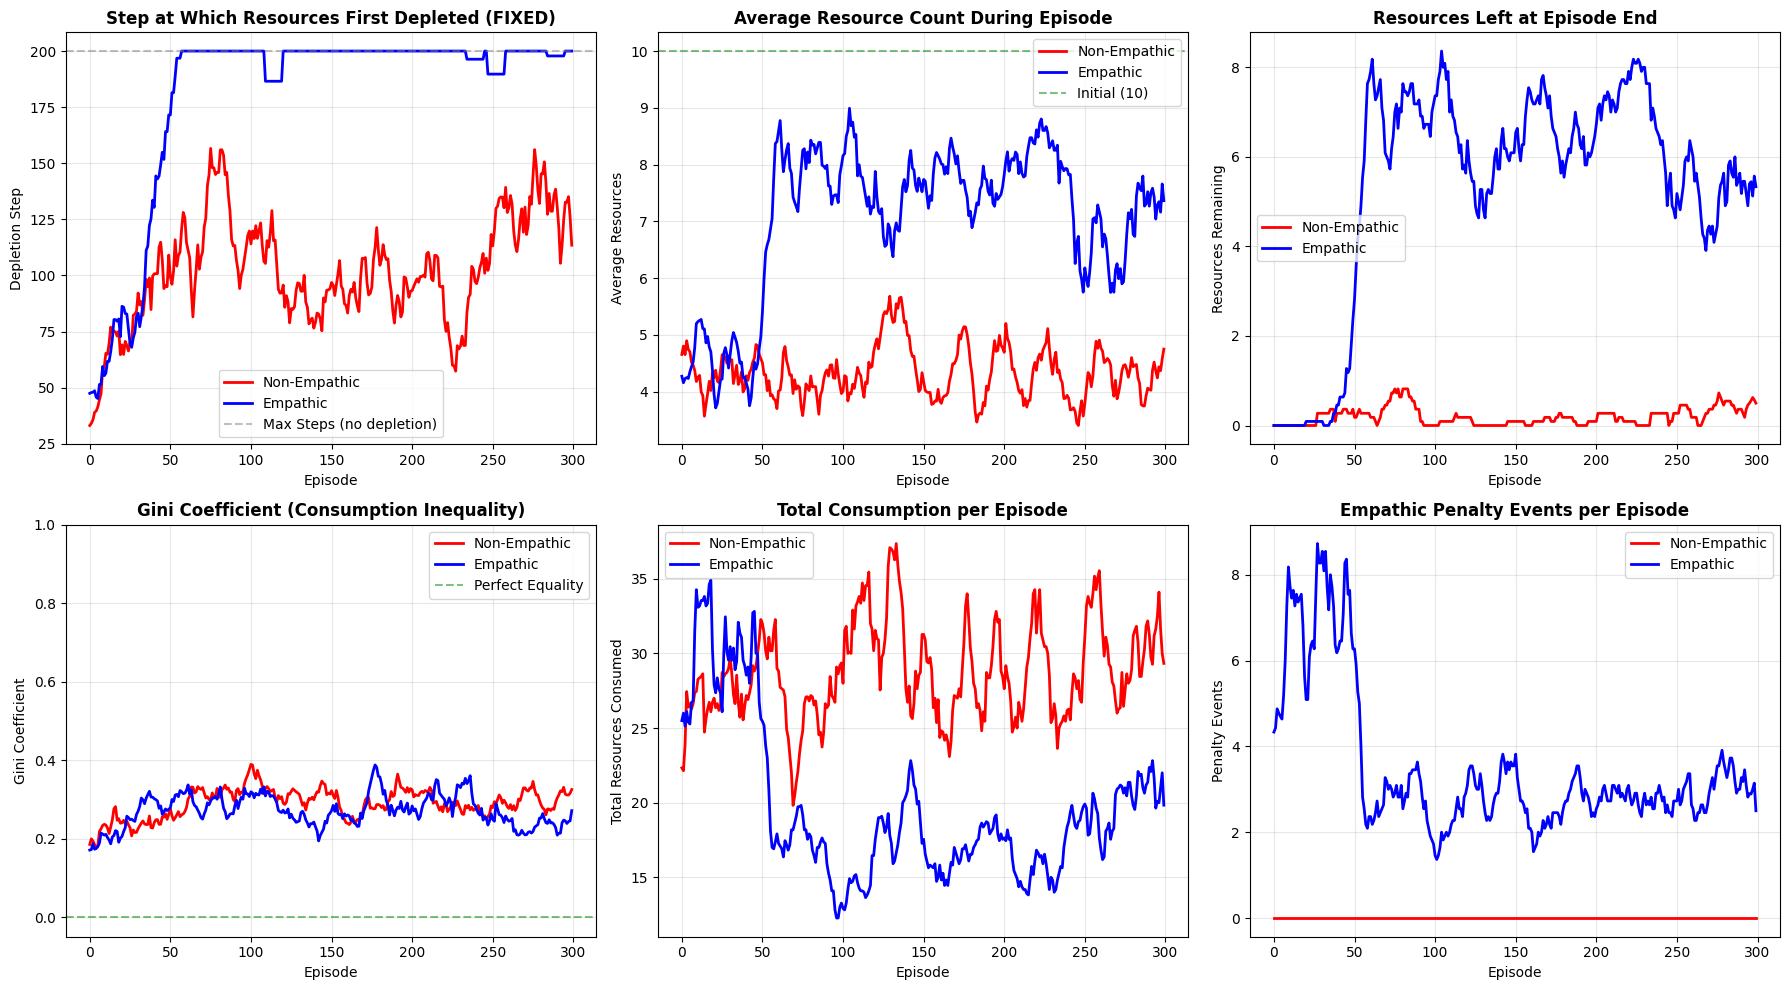


Figure saved as 'empathy_comparison_fixed_main.png'


In [ ]:
# Visualization: Main comparison figure
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

window = 10  # Smoothing window

def smooth(data, window):
    return [np.mean(data[max(0, i-window//2):min(len(data), i+window//2+1)]) for i in range(len(data))]

episodes = range(NUM_EPISODES)

# 1. Resource Depletion Step (FIXED: should now show actual depletion)
ax = axes[0, 0]
ax.plot(episodes, smooth(metrics_non_empathic['depletion_step'], window), 
        color='red', linewidth=2, label='Non-Empathic')
ax.plot(episodes, smooth(metrics_empathic['depletion_step'], window), 
        color='blue', linewidth=2, label='Empathic')
ax.axhline(y=MAX_STEPS, color='gray', linestyle='--', alpha=0.5, label='Max Steps (no depletion)')
ax.set_xlabel('Episode')
ax.set_ylabel('Depletion Step')
ax.set_title('Step at Which Resources First Depleted (FIXED)', fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)

# 2. Average Resources During Episode (NEW METRIC)
ax = axes[0, 1]
ax.plot(episodes, smooth(metrics_non_empathic['avg_resources_during_episode'], window), 
        color='red', linewidth=2, label='Non-Empathic')
ax.plot(episodes, smooth(metrics_empathic['avg_resources_during_episode'], window), 
        color='blue', linewidth=2, label='Empathic')
ax.axhline(y=10, color='green', linestyle='--', alpha=0.5, label='Initial (10)')
ax.set_xlabel('Episode')
ax.set_ylabel('Average Resources')
ax.set_title('Average Resource Count During Episode', fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)

# 3. Resources Remaining
ax = axes[0, 2]
ax.plot(episodes, smooth(metrics_non_empathic['resources_remaining'], window), 
        color='red', linewidth=2, label='Non-Empathic')
ax.plot(episodes, smooth(metrics_empathic['resources_remaining'], window), 
        color='blue', linewidth=2, label='Empathic')
ax.set_xlabel('Episode')
ax.set_ylabel('Resources Remaining')
ax.set_title('Resources Left at Episode End', fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)

# 4. Gini Coefficient (Consumption)
ax = axes[1, 0]
ax.plot(episodes, smooth(metrics_non_empathic['gini_consumption'], window), 
        color='red', linewidth=2, label='Non-Empathic')
ax.plot(episodes, smooth(metrics_empathic['gini_consumption'], window), 
        color='blue', linewidth=2, label='Empathic')
ax.axhline(y=0, color='green', linestyle='--', alpha=0.5, label='Perfect Equality')
ax.set_xlabel('Episode')
ax.set_ylabel('Gini Coefficient')
ax.set_title('Gini Coefficient (Consumption Inequality)', fontweight='bold')
ax.set_ylim(-0.05, 1.0)
ax.legend()
ax.grid(True, alpha=0.3)

# 5. Total Consumption (should now show differences)
ax = axes[1, 1]
ax.plot(episodes, smooth(metrics_non_empathic['total_consumption'], window), 
        color='red', linewidth=2, label='Non-Empathic')
ax.plot(episodes, smooth(metrics_empathic['total_consumption'], window), 
        color='blue', linewidth=2, label='Empathic')
ax.set_xlabel('Episode')
ax.set_ylabel('Total Resources Consumed')
ax.set_title('Total Consumption per Episode', fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)

# 6. Empathic Penalty Events
ax = axes[1, 2]
ax.plot(episodes, smooth(metrics_non_empathic['empathic_penalties_count'], window), 
        color='red', linewidth=2, label='Non-Empathic')
ax.plot(episodes, smooth(metrics_empathic['empathic_penalties_count'], window), 
        color='blue', linewidth=2, label='Empathic')
ax.set_xlabel('Episode')
ax.set_ylabel('Penalty Events')
ax.set_title('Empathic Penalty Events per Episode', fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('empathy_comparison_fixed_main.png', dpi=150, bbox_inches='tight')
plt.show()

print("\nFigure saved as 'empathy_comparison_fixed_main.png'")

In [ ]:
# Statistical comparison (last 20 episodes)
from scipy import stats

last_n = 20

print("="*60)
print("STATISTICAL COMPARISON (Last 20 Episodes)")
print("="*60)

def compare_metric(name, non_emp, emp):
    ne_data = non_emp[-last_n:]
    e_data = emp[-last_n:]
    
    ne_mean, ne_std = np.mean(ne_data), np.std(ne_data)
    e_mean, e_std = np.mean(e_data), np.std(e_data)
    
    # Mann-Whitney U test (non-parametric)
    try:
        stat, p_value = stats.mannwhitneyu(ne_data, e_data, alternative='two-sided')
        sig = "*" if p_value < 0.05 else ""
        sig = "**" if p_value < 0.01 else sig
        sig = "***" if p_value < 0.001 else sig
    except:
        p_value = 1.0
        sig = ""
    
    print(f"\n{name}:")
    print(f"  Non-Empathic: {ne_mean:.3f} ± {ne_std:.3f}")
    print(f"  Empathic:     {e_mean:.3f} ± {e_std:.3f}")
    print(f"  Difference:   {e_mean - ne_mean:+.3f} ({(e_mean - ne_mean) / (ne_mean + 1e-6) * 100:+.1f}%)")
    print(f"  p-value:      {p_value:.4f} {sig}")

compare_metric("Depletion Step", 
               metrics_non_empathic['depletion_step'], 
               metrics_empathic['depletion_step'])

compare_metric("Resources Remaining", 
               metrics_non_empathic['resources_remaining'], 
               metrics_empathic['resources_remaining'])

compare_metric("Avg Resources During Episode", 
               metrics_non_empathic['avg_resources_during_episode'], 
               metrics_empathic['avg_resources_during_episode'])

compare_metric("Gini (Consumption)", 
               metrics_non_empathic['gini_consumption'], 
               metrics_empathic['gini_consumption'])

compare_metric("Gini (Satisfaction)", 
               metrics_non_empathic['gini_satisfaction'], 
               metrics_empathic['gini_satisfaction'])

compare_metric("Avg Inter-Agent Distance", 
               metrics_non_empathic['avg_inter_agent_distance'], 
               metrics_empathic['avg_inter_agent_distance'])

compare_metric("Total Consumption", 
               metrics_non_empathic['total_consumption'], 
               metrics_empathic['total_consumption'])

print("\n" + "="*60)
print("Significance: * p<0.05, ** p<0.01, *** p<0.001")
print("="*60)

STATISTICAL COMPARISON (Last 20 Episodes)

Depletion Step:
  Non-Empathic: 134.800 ± 59.461
  Empathic:     198.800 ± 5.231
  Difference:   +64.000 (+47.5%)
  p-value:      0.0002 ***

Resources Remaining:
  Non-Empathic: 0.500 ± 0.671
  Empathic:     5.500 ± 2.559
  Difference:   +5.000 (+1000.0%)
  p-value:      0.0000 ***

Avg Resources During Episode:
  Non-Empathic: 4.070 ± 1.341
  Empathic:     7.452 ± 1.868
  Difference:   +3.382 (+83.1%)
  p-value:      0.0000 ***

Gini (Consumption):
  Non-Empathic: 0.292 ± 0.083
  Empathic:     0.244 ± 0.089
  Difference:   -0.048 (-16.3%)
  p-value:      0.0600 

Gini (Satisfaction):
  Non-Empathic: 0.473 ± 0.386
  Empathic:     0.260 ± 0.358
  Difference:   -0.213 (-45.0%)
  p-value:      0.0327 *

Avg Inter-Agent Distance:
  Non-Empathic: 3.806 ± 0.239
  Empathic:     4.171 ± 0.238
  Difference:   +0.365 (+9.6%)
  p-value:      0.0001 ***

Total Consumption:
  Non-Empathic: 31.000 ± 11.167
  Empathic:     21.050 ± 7.473
  Difference:   -9.